# Recomendador de cultivos por zona agrícola

Esta versión amplía la preselección para no basarse únicamente en temperatura media y lluvia. Combina:

- **NASA POWER:** temperatura media, mínima y máxima; precipitación; humedad relativa; radiación solar y viento.
- **FAO EcoCrop:** límites climáticos y requisitos disponibles de temperatura, ciclo, pH, textura, profundidad, salinidad y drenaje.
- **Datos de la zona:** coordenadas o GeoJSON, mediciones de suelo y agua de riego disponibles.

La puntuación es un filtro explicable por factores limitantes. Sin datos de análisis de suelo, disponibilidad real de agua y validación local, los resultados se presentan como candidatos provisionales o condicionados, no como una recomendación agronómica definitiva. No hay etiquetas de rendimiento local para entrenar ML supervisado.


## 1. Dependencias y entorno
Selecciona Python 3.13.17 y ejecuta la instalación con %pip. El muestreo incluye centro, anillo y puntos de prueba. NASA POWER aporta estimaciones climáticas regionales, no mediciones parcelarias.

In [115]:
%pip install --upgrade pip
%pip install numpy pandas requests matplotlib openpyxl


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [116]:
import sys, json, time, math, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

print("Python activo:", sys.version, sys.executable)
if sys.version_info < (3, 13): print("AVISO: selecciona Python 3.13.17")
CWD = Path.cwd()
ML_DIR = CWD if CWD.name.lower() == "ml" else CWD / "ml"
DATA_DIR = ML_DIR / "data"
CACHE_DIR = DATA_DIR / "power_cache"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

ZONE_NAME = "Punto de prueba (editar por zona agrícola real)"
ZONE_LAT, ZONE_LON = -13.718, -76.148
RADIUS_KM = 40.0
RING_POINTS = 8
TEST_POINTS = [
    # {"id": "muestra_1", "lat": -13.70, "lon": -76.10,
    #  "soil_ph": 6.8, "soil_texture": "medium", "soil_depth": "deep",
    #  "soil_ec_ds_m": 1.2, "soil_drainage": "well"},
]
GEOJSON_PATH = DATA_DIR / "zona_agricola.geojson"
START_DATE, END_DATE = "20150101", "20241231"
SOIL_PH = None
SOIL_TEXTURE = None
SOIL_DEPTH = None
SOIL_EC_DS_M = None
SOIL_DRAINAGE = None
IRRIGATION_MM_PER_CYCLE = None

Python activo: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)] d:\Documentos_Guille\GitHub\NASA_SPACE_APPS_HACKATON\.venv\Scripts\python.exe


## 2. Ubicación y muestreo del área (radio 40 km)
Se consultan el centro, ocho puntos equidistantes en un anillo de 40 km y los puntos opcionales de TEST_POINTS. Agrega allí los puntos reales de prueba y, si dispones de análisis, sus datos de suelo. Se rechazan ubicaciones fuera del radio. El muestreo no implica que toda el área sea parcela agrícola.

In [117]:
def _collect_lon_lat(node, found):
    if isinstance(node, (list, tuple)) and len(node) >= 2 and all(isinstance(v, (int, float)) for v in node[:2]):
        lon, lat = float(node[0]), float(node[1])
        if -180 <= lon <= 180 and -90 <= lat <= 90: found.append((lon, lat))
        return
    if isinstance(node, (list, tuple)):
        for child in node: _collect_lon_lat(child, found)

if GEOJSON_PATH.exists():
    geojson = json.loads(GEOJSON_PATH.read_text(encoding="utf-8"))
    geom = geojson.get("geometry") if geojson.get("type") == "Feature" else geojson
    coords = []
    if geojson.get("type") == "FeatureCollection":
        for f in geojson.get("features", []): _collect_lon_lat(f.get("geometry", {}).get("coordinates", []), coords)
    else: _collect_lon_lat((geom or {}).get("coordinates", []), coords)
    if not coords: raise ValueError("GeoJSON sin coordenadas válidas")
    lons, lats = zip(*coords)
    ZONE_LON, ZONE_LAT = (min(lons)+max(lons))/2, (min(lats)+max(lats))/2
    ZONE_NAME = "Zona GeoJSON: " + GEOJSON_PATH.name

def haversine_km(lat1, lon1, lat2, lon2):
    r=6371.0088; p1,p2=np.radians(lat1),np.radians(lat2)
    dp,dl=np.radians(lat2-lat1),np.radians(lon2-lon1)
    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return float(2*r*np.arcsin(np.sqrt(a)))

def destination_point(lat, lon, dist, bearing):
    r=6371.0088; p1,l1,b=np.radians(lat),np.radians(lon),np.radians(bearing); d=dist/r
    p2=np.arcsin(np.sin(p1)*np.cos(d)+np.cos(p1)*np.sin(d)*np.cos(b))
    l2=l1+np.arctan2(np.sin(b)*np.sin(d)*np.cos(p1),np.cos(d)-np.sin(p1)*np.sin(p2))
    return float(np.degrees(p2)), float((np.degrees(l2)+540)%360-180)

point_rows=[{"id":"centro","lat":ZONE_LAT,"lon":ZONE_LON,"distance_km":0.0,"source":"centro"}]
for n in range(RING_POINTS):
    bearing=360*n/RING_POINTS; lat,lon=destination_point(ZONE_LAT,ZONE_LON,RADIUS_KM,bearing)
    point_rows.append({"id":f"anillo_{bearing:03.0f}","lat":lat,"lon":lon,"distance_km":RADIUS_KM,"source":"anillo"})
soil_keys=["soil_ph","soil_texture","soil_depth","soil_ec_ds_m","soil_drainage"]
for i,p in enumerate(TEST_POINTS,1):
    lat,lon=float(p["lat"]),float(p["lon"]); dist=haversine_km(ZONE_LAT,ZONE_LON,lat,lon)
    if dist > RADIUS_KM+0.05: raise ValueError(f"Punto {p.get('id',i)} está a {dist:.1f} km; excede el radio.")
    row={"id":str(p.get("id",f"prueba_{i}")),"lat":lat,"lon":lon,"distance_km":round(dist,2),"source":"prueba"}
    row.update({k:p.get(k) for k in soil_keys}); point_rows.append(row)
sample_points=pd.DataFrame(point_rows).drop_duplicates(["lat","lon"]).reset_index(drop=True)
sample_points["id"]=[f"punto_{i+1}_{v}" for i,v in enumerate(sample_points["id"])]
print(f"{ZONE_NAME} · centro ({ZONE_LAT:.5f},{ZONE_LON:.5f}) · radio {RADIUS_KM:.0f} km")
display(sample_points)

Punto de prueba (editar por zona agrícola real) · centro (-13.71800,-76.14800) · radio 40 km


,id,lat,lon,distance_km,source
0,punto_1_centro,-13.718000,-76.148000,0.0,centro
1,punto_2_anillo_000,-13.358272,-76.148000,40.0,anillo
2,punto_3_anillo_045,-13.463497,-75.886447,40.0,anillo
3,punto_4_anillo_090,-13.717724,-75.777709,40.0,anillo
4,punto_5_anillo_135,-13.972227,-75.885879,40.0,anillo
5,punto_6_anillo_180,-14.077728,-76.148000,40.0,anillo
6,punto_7_anillo_225,-13.972227,-76.410121,40.0,anillo
7,punto_8_anillo_270,-13.717724,-76.518291,40.0,anillo
8,punto_9_anillo_315,-13.463497,-76.409553,40.0,anillo


## 3. Datos climáticos geoespaciales NASA POWER
Se consultan diariamente T2M, T2M_MIN, T2M_MAX, PRECTOTCORR, RH2M, ALLSKY_SFC_SW_DWN y WS10M en cada ubicación. Se guarda caché local. Las variables de humedad, radiación y viento son contexto, no factores puntuados sin umbrales EcoCrop comparables.

In [118]:
POWER_URL="https://power.larc.nasa.gov/api/temporal/daily/point"
NASA_PARAMETERS="T2M,T2M_MIN,T2M_MAX,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN,WS10M"
WEATHER_COLS=NASA_PARAMETERS.split(",")

def request_power_point(point):
    key=hashlib.sha1(f"{point['lat']:.5f},{point['lon']:.5f},{START_DATE},{END_DATE}".encode()).hexdigest()[:16]
    csv_path=CACHE_DIR/f"power_{key}.csv"; json_path=CACHE_DIR/f"power_{key}.json"
    if csv_path.exists() and json_path.exists():
        return pd.read_csv(csv_path,index_col=0,parse_dates=True), json.loads(json_path.read_text(encoding="utf-8"))
    params={"parameters":NASA_PARAMETERS,"community":"AG","longitude":point["lon"],"latitude":point["lat"],
            "start":START_DATE,"end":END_DATE,"format":"JSON","time-standard":"UTC"}
    response=requests.get(POWER_URL,params=params,timeout=180); response.raise_for_status(); data=response.json()
    values=data.get("properties",{}).get("parameter",{})
    missing=[c for c in WEATHER_COLS if c not in values]
    if missing: raise ValueError(f"NASA POWER no devolvió {missing} para {point['id']}")
    frame=pd.DataFrame(values); frame.index=pd.to_datetime(frame.index,format="%Y%m%d",errors="coerce")
    frame.index.name="date"; frame=frame.apply(pd.to_numeric,errors="coerce")
    frame=frame.replace(data.get("header",{}).get("fill_value",-999.0),np.nan).dropna(subset=WEATHER_COLS)
    frame.to_csv(csv_path,encoding="utf-8")
    header=data.get("header",{}); json_path.write_text(json.dumps(header,ensure_ascii=False),encoding="utf-8")
    return frame,header

daily_by_point={}; power_metadata_by_point={}
for _,p in sample_points.iterrows():
    frame,meta=request_power_point(p); daily_by_point[p["id"]]=frame[WEATHER_COLS].copy()
    power_metadata_by_point[p["id"]]=meta
    print(f"{p['id']}: {len(frame)} días válidos")
    time.sleep(0.25)
center_id=sample_points.iloc[0]["id"]; power_df=daily_by_point[center_id]
unit_table=pd.DataFrame(power_metadata_by_point[center_id].get("parameters",{})).T
display(unit_table[[c for c in ["units","longname"] if c in unit_table.columns]])
display(power_df.head())

punto_1_centro: 3653 días válidos
punto_2_anillo_000: 3653 días válidos
punto_3_anillo_045: 3653 días válidos
punto_4_anillo_090: 3653 días válidos
punto_5_anillo_135: 3653 días válidos
punto_6_anillo_180: 3653 días válidos
punto_7_anillo_225: 3653 días válidos
punto_8_anillo_270: 3653 días válidos
punto_9_anillo_315: 3653 días válidos


""


,T2M,T2M_MIN,T2M_MAX,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN,WS10M
date,,,,,,,
2015-01-01,21.24,18.07,25.00,0.22,73.46,17.27,4.15
2015-01-02,19.95,17.70,22.25,0.56,81.04,23.51,3.68
2015-01-03,21.06,17.84,26.24,0.00,74.09,25.41,4.11
2015-01-04,21.40,18.69,24.62,0.00,71.83,20.51,3.72
2015-01-05,21.90,18.51,25.93,0.34,70.59,24.67,4.08


,promedio
temp_mean_c,18.95
rain_mm,95.90


,temp_mean_c,rain_mm,temp_min_c,temp_max_c,humidity_pct,solar,wind
mes,,,,,,,
1,20.33,15.94,15.76,26.75,73.71,23.19,3.66
2,20.99,20.52,16.91,27.09,75.15,22.49,3.44
3,20.93,15.90,16.66,27.10,74.63,21.78,3.40
4,20.03,6.13,15.12,26.69,70.97,21.27,3.63
5,18.84,3.70,13.51,25.78,65.52,18.14,3.71
6,17.63,1.20,12.29,25.00,64.25,14.86,3.86
7,17.27,1.45,11.77,24.70,62.88,15.31,4.13
8,17.41,1.15,11.80,24.65,59.92,17.50,4.16
9,17.83,2.89,12.30,25.10,59.95,20.36,4.23


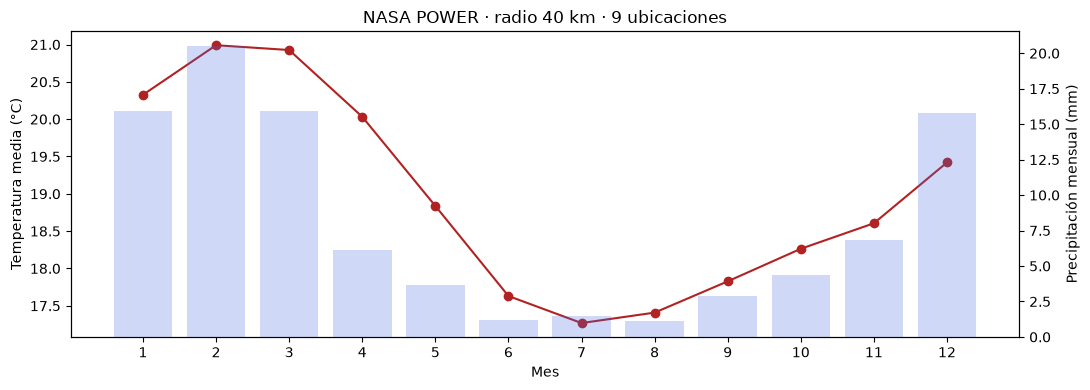

In [119]:
# Resumen mensual promedio de todos los puntos muestreados
month_rows=[]; annual_rows=[]
for pid,df in daily_by_point.items():
    m=df.groupby([df.index.year,df.index.month]).agg(temp_mean_c=("T2M","mean"),rain_mm=("PRECTOTCORR","sum"),
        temp_min_c=("T2M_MIN","min"),temp_max_c=("T2M_MAX","max"),humidity_pct=("RH2M","mean"),
        solar=("ALLSKY_SFC_SW_DWN","mean"),wind=("WS10M","mean")).reset_index(names=["anio","mes"])
    m["punto_id"]=pid; month_rows.append(m)
    a=df.groupby(df.index.year).agg(temp_mean_c=("T2M","mean"),rain_mm=("PRECTOTCORR","sum")).reset_index(names="anio")
    a["punto_id"]=pid; annual_rows.append(a)
monthly_by_year_all=pd.concat(month_rows,ignore_index=True)
monthly_climatology=monthly_by_year_all.groupby("mes")[["temp_mean_c","rain_mm","temp_min_c","temp_max_c","humidity_pct","solar","wind"]].mean()
monthly_climatology.index.name="mes"
annual_climatology=pd.concat(annual_rows,ignore_index=True)
display(annual_climatology[["temp_mean_c","rain_mm"]].mean().to_frame("promedio").round(2))
display(monthly_climatology.round(2))
fig,ax1=plt.subplots(figsize=(11,4)); months=monthly_climatology.index.to_numpy()
ax1.plot(months,monthly_climatology["temp_mean_c"],marker="o",color="firebrick")
ax1.set_xlabel("Mes"); ax1.set_ylabel("Temperatura media (°C)"); ax1.set_xticks(range(1,13))
ax2=ax1.twinx(); ax2.bar(months,monthly_climatology["rain_mm"],alpha=.25,color="royalblue")
ax2.set_ylabel("Precipitación mensual (mm)")
plt.title(f"NASA POWER · radio {RADIUS_KM:.0f} km · {len(sample_points)} ubicaciones")
plt.tight_layout(); plt.show()

## 4. Perfiles de cultivos: FAO EcoCrop

EcoCrop contiene límites de temperatura y precipitación, ciclo, pH, textura, profundidad, salinidad y drenaje, pero no todos los campos están completos para todas las especies. Para no llenar faltantes con supuestos, cada factor de suelo solo se puntúa cuando hay una medición de la zona y un requisito disponible del cultivo. Además, se filtran especies a categorías de cultivos alimentarios (cereales, legumbres, raíces/tubérculos, hortalizas y frutas/nueces) y se muestra el nombre científico junto con un nombre común principal.


In [120]:
ECOCROP_URL = "https://raw.githubusercontent.com/OpenCLIM/ecocrop/main/EcoCrop_DB.csv"
ECOCROP_FILE = DATA_DIR / "EcoCrop_DB.csv"
if not ECOCROP_FILE.exists():
    eco_response = requests.get(ECOCROP_URL, timeout=90)
    eco_response.raise_for_status()
    ECOCROP_FILE.write_bytes(eco_response.content)

ecocrop = pd.read_csv(ECOCROP_FILE, low_memory=False, encoding="latin-1")
ecocrop.columns = [str(c).strip().upper() for c in ecocrop.columns]
required_columns = ["TMIN", "TOPMN", "TOPMX", "TMAX", "ROPMN", "ROPMX", "RMIN", "RMAX", "GMIN", "GMAX"]
missing_columns = [c for c in required_columns if c not in ecocrop.columns]
if missing_columns:
    raise ValueError(f"EcoCrop cambió de estructura; faltan columnas: {missing_columns}")

for col in set(required_columns + ["PHMIN", "PHOPMN", "PHOPMX", "PHMAX", "ALTMX", "GMIN", "GMAX", "KTMP"]):
    if col in ecocrop.columns:
        ecocrop[col] = pd.to_numeric(ecocrop[col], errors="coerce")

name_column = "COMNAME" if "COMNAME" in ecocrop.columns else "SCIENTIFICNAME"
if name_column not in ecocrop.columns:
    raise ValueError("EcoCrop no contiene nombres comunes ni científicos.")
print("Perfiles EcoCrop cargados:", len(ecocrop))
print("Categorías de uso presentes:", ecocrop["CAT"].dropna().astype(str).str.split(", ").explode().unique()[:20])
display(ecocrop[[name_column, "SCIENTIFICNAME", "CAT"] + required_columns].head())


Perfiles EcoCrop cargados: 2568
Categorías de uso presentes: <StringArray>
[             'vegetables',        'ornamentals/turf',
   'medicinals & aromatic',             'forest/wood',
               'materials',           'environmental',
          'forage/pasture', 'cereals & pseudocereals',
           'fruits & nuts',              'cover crop',
                    'weed',            'roots/tubers',
  'pulses (grain legumes)',                   'other']
Length: 14, dtype: str


,COMNAME,SCIENTIFICNAME,CAT,TMIN,TOPMN,TOPMX,TMAX,ROPMN,ROPMX,RMIN,RMAX,GMIN,GMAX
0,"abelmoskus, america-neri, bakhua mun, bamia, b...",Abelmoschus esculentus,vegetables,12.0,20.0,30.0,35.0,600.0,1200.0,300.0,2500.0,50.0,180.0
1,"neka (Simbo), bele (Fiji), pele (Tonga, Tuvalu...",Abelmoschus manihot,"vegetables, ornamentals/turf, medicinals & aro...",16.0,22.0,30.0,36.0,1200.0,2000.0,1000.0,3000.0,365.0,365.0
2,"abelmosk, musk mallow, mushkdan, muskdana, kas...",Abelmoschus moschatus,"ornamentals/turf, medicinals & aromatic",10.0,20.0,30.0,35.0,1000.0,1400.0,900.0,1500.0,0.0,0.0
3,"Papuan wattle, auri, ear leaf acacia, tuhkehn ...",Acacia auriculiformis,forest/wood,10.0,24.0,32.0,40.0,1200.0,2500.0,500.0,5000.0,180.0,240.0
4,"Ellington curse, klu, cassie, espino blanco, a...",Acacia farnesiana,"materials, ornamentals/turf, medicinals & arom...",7.0,20.0,32.0,42.0,400.0,1400.0,150.0,4000.0,60.0,240.0


## 5. Método de puntuación y variables que faltaban

El algoritmo evalúa ventanas de cultivo de `GMIN`, el punto medio y `GMAX`, con fechas iniciales cada siete días. Puntúa la temperatura media y lluvia acumulada del ciclo con los rangos EcoCrop. Incorpora heladas (temperatura mínima bajo `KTMP`) y días de calor extremo (`T2M_MAX` sobre el máximo del perfil), según la lógica de aptitud climática de EcoCrop. El score climático del escenario actual es el factor limitante entre temperatura y lluvia; los datos de suelo medidos también pueden limitarlo.

Las variables del usuario son pH, textura, profundidad, salinidad (conductividad eléctrica), drenaje y agua de riego disponible. NASA aporta además humedad relativa, radiación y viento para diagnóstico, no para el score, porque la base no entrega umbrales por cultivo comparables para todos esos indicadores. Si no se proporciona agua de riego, los candidatos con buen ajuste térmico y déficit de lluvia se etiquetan **condicionados a riego**, no como recomendaciones confirmadas.

Si todos los scores actuales son cero, el notebook debe mostrar que no hay candidatos para temporal, no ordenar cultivos con cero como si fueran recomendaciones. El score no es rendimiento ni probabilidad de éxito.


In [121]:
def suitability_score(values, absolute_min, optimum_min, optimum_max, absolute_max):
    """Curva trapezoidal 0–100 basada en límites absolutos y óptimos EcoCrop."""
    x = np.asarray(values, dtype=float)
    lo, opt_lo, opt_hi, hi = map(float, (absolute_min, optimum_min, optimum_max, absolute_max))
    if not np.isfinite([lo, opt_lo, opt_hi, hi]).all() or not lo < opt_lo <= opt_hi < hi:
        return np.full(x.shape, np.nan, dtype=float)
    score = np.zeros(x.shape, dtype=float)
    finite = np.isfinite(x)
    rising = finite & (x > lo) & (x < opt_lo)
    plateau = finite & (x >= opt_lo) & (x <= opt_hi)
    falling = finite & (x > opt_hi) & (x < hi)
    score[rising] = 100 * (x[rising] - lo) / (opt_lo - lo)
    score[plateau] = 100
    score[falling] = 100 * (hi - x[falling]) / (hi - opt_hi)
    return score

def _profile_text(row, col):
    value = row.get(col, np.nan)
    return "" if pd.isna(value) else str(value).strip().lower()

def _norm_texture(value):
    if value is None:
        return ""
    text = str(value).strip().lower()
    aliases = {"sandy": "light", "coarse": "light", "loamy": "medium", "loam": "medium", "clayey": "heavy", "clay": "heavy", "peat": "organic"}
    return aliases.get(text, text)

def soil_scores_for_crop(row, soil=None):
    """Puntúa únicamente propiedades observadas y requisitos EcoCrop disponibles."""
    soil = soil or {}
    ph = soil.get("soil_ph", SOIL_PH)
    texture = soil.get("soil_texture", SOIL_TEXTURE)
    depth = soil.get("soil_depth", SOIL_DEPTH)
    ec = soil.get("soil_ec_ds_m", SOIL_EC_DS_M)
    drainage = soil.get("soil_drainage", SOIL_DRAINAGE)
    scores = {}
    if ph is not None and all(pd.notna(row.get(c, np.nan)) for c in ["PHMIN", "PHOPMN", "PHOPMX", "PHMAX"]):
        scores["score_ph"] = float(suitability_score([ph], row.PHMIN, row.PHOPMN, row.PHOPMX, row.PHMAX)[0])
    if texture is not None:
        observed = _norm_texture(texture)
        optimal, tolerance = _norm_texture(_profile_text(row, "TEXT")), _norm_texture(_profile_text(row, "TEXTR"))
        if optimal or tolerance:
            scores["score_textura"] = 100.0 if observed == optimal or optimal == "wide" else (70.0 if observed == tolerance or tolerance == "wide" else 0.0)
    if depth is not None:
        ranks = {"shallow": 1, "medium": 2, "deep": 3}
        actual = ranks.get(str(depth).strip().lower(), 0)
        optimal = next((ranks[k] for k in ranks if k in _profile_text(row, "DEP")), 0)
        tolerance = next((ranks[k] for k in ranks if k in _profile_text(row, "DEPR")), 0)
        if actual and optimal:
            scores["score_profundidad"] = 100.0 if actual >= optimal else (60.0 if actual >= tolerance > 0 else 0.0)
    if ec is not None:
        def max_ec(label):
            text = str(label).lower()
            nums = [float(x) for x in __import__("re").findall(r"\d+(?:\.\d+)?", text)]
            if ">" in text and nums: return float("inf")
            if nums: return max(nums)
            if "high" in text: return float("inf")
            if "medium" in text: return 10.0
            if "low" in text: return 4.0
            return np.nan
        optimal_ec, tolerance_ec = max_ec(row.get("SAL", "")), max_ec(row.get("SALR", ""))
        if np.isfinite(tolerance_ec) or tolerance_ec == float("inf"):
            scores["score_salinizacion"] = 100.0 if ec <= optimal_ec else (60.0 if ec <= tolerance_ec else 0.0)
    if drainage is not None:
        observed = str(drainage).strip().lower()
        optimal, tolerance = _profile_text(row, "DRA"), _profile_text(row, "DRAR")
        key = "poorly" if "poor" in observed else ("excessive" if "excess" in observed else "well")
        if optimal or tolerance:
            scores["score_drenaje"] = 100.0 if key in optimal else (60.0 if key in tolerance else 0.0)
    return scores

# Filtra especies alimentarias, conserva perfiles con clima/ciclo válido y crea alias cortos.
food_pattern = r"cereals & pseudocereals|pulses \(grain legumes\)|roots/tubers|vegetables|fruits & nuts"
food_mask = ecocrop.get("CAT", pd.Series("", index=ecocrop.index)).fillna("").astype(str).str.lower().str.contains(food_pattern, regex=True)
valid_profiles = ecocrop[food_mask].copy()
for col in required_columns:
    valid_profiles[col] = pd.to_numeric(valid_profiles[col], errors="coerce")
valid_profiles["_name"] = valid_profiles[name_column].fillna("").astype(str).str.split(",").str[0].str.strip()
valid_profiles = valid_profiles[
    valid_profiles["_name"].ne("")
    & valid_profiles[required_columns].notna().all(axis=1)
    & (valid_profiles["TMIN"] < valid_profiles["TOPMN"])
    & (valid_profiles["TOPMN"] <= valid_profiles["TOPMX"])
    & (valid_profiles["TOPMX"] < valid_profiles["TMAX"])
    & (valid_profiles["RMIN"] < valid_profiles["ROPMN"])
    & (valid_profiles["ROPMN"] <= valid_profiles["ROPMX"])
    & (valid_profiles["ROPMX"] < valid_profiles["RMAX"])
    & (valid_profiles["GMIN"] >= 1)
    & (valid_profiles["GMAX"] <= 365)
    & (valid_profiles["GMIN"] <= valid_profiles["GMAX"])
].copy()

# Precalcula las ventanas por ubicación; no rellena datos faltantes con cero.
durations_by_row,all_durations={},set()
for idx,row in valid_profiles.iterrows():
    low,high=int(round(row.GMIN)),int(round(row.GMAX))
    durations_by_row[idx]=sorted({low,int(round((low+high)/2)),high}); all_durations.update(durations_by_row[idx])
window_cache_by_point={}
for point_id,raw in daily_by_point.items():
    daily=raw[WEATHER_COLS].sort_index().copy(); daily=daily[~daily.index.duplicated(keep="first")]
    daily=daily.reindex(pd.date_range(daily.index.min(),daily.index.max(),freq="D"))
    cache={}; years_all=daily.index.year.to_numpy()
    for duration in sorted(all_durations):
        if duration>len(daily): continue
        rolling={"temp":daily["T2M"].rolling(duration,min_periods=duration).mean().to_numpy(),
            "rain":daily["PRECTOTCORR"].rolling(duration,min_periods=duration).sum().to_numpy(),
            "tmin":daily["T2M_MIN"].rolling(duration,min_periods=duration).min().to_numpy(),
            "tmax":daily["T2M_MAX"].rolling(duration,min_periods=duration).max().to_numpy(),
            "humidity":daily["RH2M"].rolling(duration,min_periods=duration).mean().to_numpy(),
            "solar":daily["ALLSKY_SFC_SW_DWN"].rolling(duration,min_periods=duration).mean().to_numpy(),
            "wind":daily["WS10M"].rolling(duration,min_periods=duration).mean().to_numpy()}
        starts=np.arange(0,len(daily)-duration+1,7,dtype=int); ends=starts+duration-1
        same=years_all[starts]==years_all[ends]; starts,ends=starts[same],ends[same]
        cache[duration]=(starts,{k:v[ends] for k,v in rolling.items()},years_all[starts],daily.index)
    window_cache_by_point[point_id]=cache
print("Perfiles válidos:",len(valid_profiles),"· ubicaciones:",len(window_cache_by_point))

Perfiles válidos: 499 · ubicaciones: 9


In [122]:
# Puntúa cada cultivo en cada punto, y luego resume la variación espacial.
soil_factor_names=["score_ph","score_textura","score_profundidad","score_salinizacion","score_drenaje"]
rows=[]
for idx,crop in valid_profiles.iterrows():
  for _,point in sample_points.iterrows():
    pid=point["id"]; soil={k:point.get(k) for k in soil_keys if pd.notna(point.get(k))}
    soil_parts=soil_scores_for_crop(crop,soil); soil_floor=min(soil_parts.values()) if soil_parts else 100.0
    actual_best={}; cond_best={}
    for duration in durations_by_row[idx]:
      cached=window_cache_by_point[pid].get(duration)
      if cached is None: continue
      starts,stats,years,dates=cached
      temp=suitability_score(stats["temp"],crop.TMIN,crop.TOPMN,crop.TOPMX,crop.TMAX)
      ktmp=crop.get("KTMP",np.nan)
      if pd.notna(ktmp): temp=temp.copy(); temp[stats["tmin"]<float(ktmp)]=0.0
      hot=(daily_by_point[pid]["T2M_MAX"].reindex(dates).to_numpy()>float(crop.TMAX)).astype(int)
      hotprefix=np.r_[0,np.cumsum(hot)]; hotdays=hotprefix[starts+duration]-hotprefix[starts]
      temp=np.maximum(0,temp-hotdays)
      rain=suitability_score(stats["rain"]+(float(IRRIGATION_MM_PER_CYCLE) if IRRIGATION_MM_PER_CYCLE is not None else 0),crop.RMIN,crop.ROPMN,crop.ROPMX,crop.RMAX)
      actual=np.minimum(np.minimum(temp,rain),soil_floor); conditional=np.minimum(temp,soil_floor)
      for year in np.unique(years):
        loc=np.flatnonzero(years==year)
        if np.isfinite(actual[loc]).any(): actual_best[int(year)]=max(actual_best.get(int(year),0),float(np.nanmax(actual[loc])))
        if np.isfinite(conditional[loc]).any(): cond_best[int(year)]=max(cond_best.get(int(year),0),float(np.nanmax(conditional[loc])))
    if not cond_best: continue
    rain_mean=float(np.nanmean(daily_by_point[pid]["PRECTOTCORR"]))*int(round((crop.GMIN+crop.GMAX)/2))
    rows.append({"punto_id":pid,"lat":point["lat"],"lon":point["lon"],"distancia_centro_km":point["distance_km"],
      "cultivo_comun":crop["_name"],"nombre_cientifico":crop.get("SCIENTIFICNAME",""),"categoria":crop.get("CAT",""),
      "score_actual_0_100":float(np.mean(list(actual_best.values()))) if actual_best else 0.0,
      "score_condicional_agua_0_100":float(np.mean(list(cond_best.values()))),
      "deficit_hasta_minimo_ecocrop_mm":max(0.0,float(crop.RMIN)-rain_mean),**soil_parts})
point_results=pd.DataFrame(rows)
if point_results.empty: raise ValueError("No hay perfiles EcoCrop evaluables en estas fechas y ubicaciones.")
all_candidates=point_results.groupby(["cultivo_comun","nombre_cientifico","categoria"],as_index=False).agg(
  score_escenario_actual_0_100=("score_actual_0_100","mean"),
  score_condicional_con_agua_0_100=("score_condicional_agua_0_100","mean"),
  score_min_puntos=("score_actual_0_100","min"),score_max_puntos=("score_actual_0_100","max"),
  puntos_con_score_positivo=("score_actual_0_100",lambda x:int((x>0).sum())),
  puntos_evaluados=("punto_id","nunique"),deficit_medio_hasta_minimo_ecocrop_mm=("deficit_hasta_minimo_ecocrop_mm","mean"))
for factor in ["score_ph", "score_textura", "score_profundidad", "score_salinizacion", "score_drenaje"]:
  if factor in point_results:
    means=point_results.groupby(["cultivo_comun","nombre_cientifico","categoria"])[factor].mean()
    all_candidates[factor]=all_candidates.set_index(["cultivo_comun","nombre_cientifico","categoria"]).index.map(means)
all_candidates["fraccion_puntos_con_score_positivo"]=all_candidates["puntos_con_score_positivo"]/all_candidates["puntos_evaluados"]
all_candidates["estado"]=np.where(all_candidates["score_escenario_actual_0_100"]>0,"CANDIDATO_PROVISIONAL","NO_OPTIMO")
all_candidates=all_candidates.sort_values(["score_escenario_actual_0_100","fraccion_puntos_con_score_positivo","score_condicional_con_agua_0_100"],ascending=False).reset_index(drop=True)
all_candidates.insert(0,"puesto",np.arange(1,len(all_candidates)+1))
recommendations=all_candidates[all_candidates["score_escenario_actual_0_100"]>0].copy()
conditional_candidates=all_candidates[(all_candidates["score_condicional_con_agua_0_100"]>0)&(all_candidates["score_escenario_actual_0_100"]<=0)].copy()

def manejo_sugerido(row):
  advice=[]
  if row["deficit_medio_hasta_minimo_ecocrop_mm"]>0:
    advice.append("Agua: confirmar fuente, calidad y volumen de riego; revisar calendario y cultivar.")
  soil_measured=any(v is not None for v in [SOIL_PH,SOIL_TEXTURE,SOIL_DEPTH,SOIL_EC_DS_M,SOIL_DRAINAGE]) or any(
      any(pd.notna(p.get(k)) for k in soil_keys) for p in TEST_POINTS)
  if not soil_measured:
    advice.append("Suelo: tomar análisis por ubicación de pH, conductividad eléctrica/salinidad, textura, profundidad, drenaje y nutrientes; no aplicar enmiendas a ciegas.")
  else:
    if pd.notna(row.get("score_ph")) and row["score_ph"]<60:
      advice.append("pH: consultar al laboratorio la corrección adecuada; cal solo si el suelo es ácido y acidificación solo si se confirma alcalinidad; sin dosis automáticas.")
    if pd.notna(row.get("score_salinizacion")) and row["score_salinizacion"]<60:
      advice.append("Salinidad: analizar también el agua y verificar drenaje; lavado de sales únicamente con agua apta y drenaje funcional.")
    if pd.notna(row.get("score_drenaje")) and row["score_drenaje"]<60:
      advice.append("Drenaje: revisar encharcamiento, compactación y nivel freático; evaluar canales o camas elevadas con asistencia local.")
    if pd.notna(row.get("score_textura")) and row["score_textura"]<60:
      advice.append("Textura: priorizar cultivos/variedades compatibles; evaluar cobertura y materia orgánica madura según análisis local.")
    if pd.notna(row.get("score_profundidad")) and row["score_profundidad"]<60:
      advice.append("Profundidad: confirmar capas limitantes y elegir raíces compatibles; evitar subsolado sin verificar el perfil.")
    if len(advice)==0 or (len(advice)==1 and advice[0].startswith("Agua:")):
      advice.append("Suelo: los datos disponibles no identifican una enmienda específica; mantener manejo guiado por análisis local.")
  advice.append("Clima: evaluar calendario y variedades adaptadas; alternativa NO ÓPTIMA, validar primero en parcela.")
  return " ".join(advice)
if recommendations.empty:
  print("No hay candidato con ajuste positivo. Estas cinco alternativas son NO ÓPTIMAS; sirven para orientar pruebas, no para recomendar siembra.")
  fallback=all_candidates.sort_values(["score_condicional_con_agua_0_100","score_max_puntos"],ascending=False).head(5).copy()
  fallback["estado"]="NO OPTIMO - requiere diagnóstico/validación"
  fallback["manejo_a_evaluar"]=fallback.apply(manejo_sugerido,axis=1)
  display(fallback); recommendations_to_export=fallback
else:
  print("Candidatos provisionales: promedio, rango y proporción de puntos con score positivo.")
  display(recommendations.head(20)); recommendations_to_export=recommendations
print("Puntos consultados:",len(sample_points),"; usar datos de suelo por TEST_POINTS cuando existan.")

Candidatos provisionales: promedio, rango y proporción de puntos con score positivo.


,puesto,cultivo_comun,nombre_cientifico,categoria,score_escenario_actual_0_100,score_condicional_con_agua_0_100,score_min_puntos,score_max_puntos,puntos_con_score_positivo,puntos_evaluados,deficit_medio_hasta_minimo_ecocrop_mm,fraccion_puntos_con_score_positivo,estado
0,1,date palm,Phoenix dactylifera,fruits & nuts,11.924968,56.665049,0.0,36.056901,3,9,36.192825,0.333333,CANDIDATO_PROVISIONAL
1,2,snotappel,Azanza garckeana,"forage/pasture, fruits & nuts, vegetables, mat...",11.111111,100.000000,0.0,50.000000,2,9,108.529207,0.222222,CANDIDATO_PROVISIONAL
2,3,River cooba,Acacia stenophylla,"forage/pasture, fruits & nuts, forest/wood, en...",11.024117,97.474986,0.0,45.734026,3,9,60.622730,0.333333,CANDIDATO_PROVISIONAL
3,4,mobola-plum,Parinari curatellifolia,"forage/pasture, fruits & nuts, materials, orna...",10.216481,100.000000,0.0,38.473333,3,9,36.192825,0.333333,CANDIDATO_PROVISIONAL
4,5,jojoba,Simmondsia chinensis,"forage/pasture, fruits & nuts, materials, medi...",8.347728,89.354579,0.0,34.091778,3,9,52.654112,0.333333,CANDIDATO_PROVISIONAL
5,6,karsatta (Konsogna),Dobera glabra,"forage/pasture, fruits & nuts, materials, orna...",8.117998,77.767549,0.0,45.005000,3,9,36.192825,0.333333,CANDIDATO_PROVISIONAL
6,7,dom (Sudan),Hyphaene thebaica,"forage/pasture, fruits & nuts, vegetables, mat...",8.067808,57.785412,0.0,30.368637,3,9,41.452693,0.333333,CANDIDATO_PROVISIONAL
7,8,tooth brush tree,Salvadora persica,"forage/pasture, fruits & nuts, materials, medi...",6.764444,100.000000,0.0,30.440000,2,9,108.529207,0.222222,CANDIDATO_PROVISIONAL
8,9,Bramble wattle,Acacia victoriae,"forage/pasture, fruits & nuts, materials, fore...",6.636833,100.000000,0.0,27.261000,3,9,56.685003,0.333333,CANDIDATO_PROVISIONAL
9,10,marula,Sclerocarya birrea ssp. caffra,"forage/pasture, fruits & nuts, materials, orna...",3.318519,81.472958,0.0,14.933333,2,9,108.529207,0.222222,CANDIDATO_PROVISIONAL


Puntos consultados: 9 ; usar datos de suelo por TEST_POINTS cuando existan.


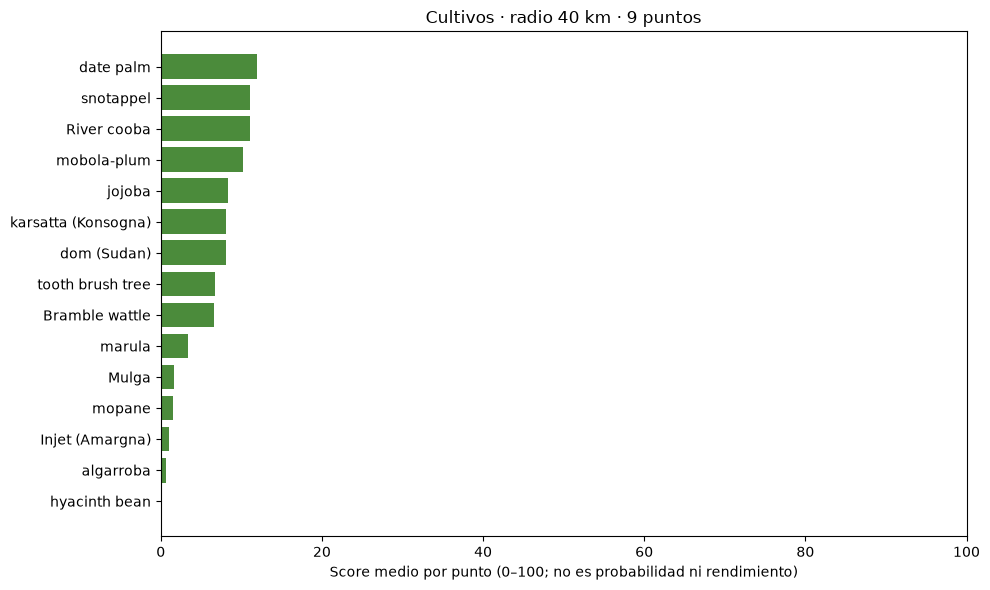

In [123]:
plot_data=recommendations if not recommendations.empty else fallback
top=plot_data.head(15).sort_values("score_escenario_actual_0_100")
plt.figure(figsize=(10,6))
plt.barh(top["cultivo_comun"],top["score_escenario_actual_0_100"],color="#4b8b3b")
plt.xlabel("Score medio por punto (0–100; no es probabilidad ni rendimiento)")
plt.title(f"Cultivos · radio {RADIUS_KM:.0f} km · {len(sample_points)} puntos")
plt.xlim(0,100); plt.tight_layout(); plt.show()

## 6. Interpretación, manejo y alcance
El score del área es un promedio de ubicaciones; score_min_puntos, score_max_puntos y fraccion_puntos_con_score_positivo describen su variación. Candidato provisional no significa rendimiento esperado ni éxito garantizado. Si no hay score positivo se listan cinco alternativas no óptimas para orientar pruebas y diagnóstico.

Si la limitación es lluvia, verificar fuente, calidad y cantidad de agua y ajustar calendario/cultivar. Si faltan datos de suelo, muestrear por separado cada punto. No aplicar cal, azufre, yeso ni hacer lavado de sales sin diagnóstico: las enmiendas dependen del análisis de suelo/agua y el lavado requiere agua y drenaje adecuados ([FAO, suelos afectados por salinidad](https://www.fao.org/soils-portal/soil-management/manejo-de-suelos-problematicos/suelos-afectados-por-salinidad/more-information-on-salt-affected-soils/es)); la cal requiere un análisis de pH y capacidad tampón ([UMN Extension](https://extension.umn.edu/agriculture/crop-production/nutrient-management-for-minnesota-crops/lime-needs-minnesota)).

El radio de 40 km define los puntos consultados, no la superficie exacta de cultivo. POWER usa celdas climáticas regionales; puntos vecinos pueden compartir celda y no son mediciones de parcela. El modelo no incorpora rendimiento local ni relieve detallado. Contrastar con fuentes agronómicas y análisis de campo.

In [124]:
# Guarda ranking del área, detalle punto a punto y metadatos actuales
recommendations_path=DATA_DIR/"recomendaciones_cultivos.csv"
points_path=DATA_DIR/"recomendaciones_por_punto.csv"
fallback_path=DATA_DIR/"alternativas_no_optimas.csv"
monthly_path=DATA_DIR/"climatologia_mensual_power.csv"
metadata_path=DATA_DIR/"metadata_fuentes.json"
recommendations_to_export.to_csv(recommendations_path,index=False,encoding="utf-8-sig")
point_results.to_csv(points_path,index=False,encoding="utf-8-sig")
if recommendations.empty: fallback.to_csv(fallback_path,index=False,encoding="utf-8-sig")
elif fallback_path.exists(): fallback_path.unlink()
monthly_climatology.to_csv(monthly_path,encoding="utf-8-sig")
metadata_path.write_text(json.dumps({"zona":ZONE_NAME,"latitud":ZONE_LAT,"longitud":ZONE_LON,"radio_km":RADIUS_KM,
  "puntos":sample_points.to_dict(orient="records"),"periodo_inicio":START_DATE,"periodo_fin":END_DATE,
  "fuente_clima":"NASA POWER Daily API","variables":NASA_PARAMETERS.split(","),
  "metodo":"score EcoCrop por punto; promedio y variabilidad en el radio; cinco alternativas no óptimas si no hay score positivo",
  "nota":"clima regional, no resolución parcelaria; salidas no son rendimiento ni prescripción agronómica"},
  ensure_ascii=False,indent=2,default=str),encoding="utf-8")
print("Ranking:",recommendations_path.resolve())
print("Detalle por punto:",points_path.resolve())
if recommendations.empty: print("Alternativas no óptimas:",fallback_path.resolve())
print("Climatología y metadatos:",DATA_DIR.resolve())

Ranking: D:\Documentos_Guille\GitHub\NASA_SPACE_APPS_HACKATON\ml\data\recomendaciones_cultivos.csv
Detalle por punto: D:\Documentos_Guille\GitHub\NASA_SPACE_APPS_HACKATON\ml\data\recomendaciones_por_punto.csv
Climatología y metadatos: D:\Documentos_Guille\GitHub\NASA_SPACE_APPS_HACKATON\ml\data
